# **Data leakage**

This notebook repeats the pipeline of one published study on the HCV data and then repeats it with the steps in a different order. In the published pipeline, SMOTE (a method that creates synthetic patients) runs on the whole dataset before it is split into training, validation and test sets. In the corrected pipeline the patients are split first and every step learns from the training rows only. The models and settings are the same in both, so the order of the steps is the only difference.

The study is Das N, Hossain MB, Adhikary A, Raha AD, Qiao Y, Hassan MM, Bairagi AK (2025) 'Enlightened prognosis: Hepatitis prediction with an explainable machine learning approach', *PLoS ONE*, 20(3), e0319078, doi 10.1371/journal.pone.0319078. The study keeps all 615 rows and all five classes. Its workflow figure (Fig 1) shows SMOTE inside preprocessing, before "Splitting Dataset". Its confusion matrices have 400 test rows, 81 of them in the suspect blood donor class.

# **Importing Libraries**

In [1]:
# importing necessary libraries / dependencies
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# **Loading the DataFrame**

In [2]:
# retrieving the raw dataset (missing values are left in)
df = pd.read_csv('hcvdat0.csv')

# dropping the row number column
df = df.drop(columns=['Unnamed: 0'])

# removing the number before the = sign in the labels
df['Category'] = df['Category'].str.replace(r'^[^=]*=', '', regex=True)

# encoding the target into five integer labels in a fixed order
classes = ['Blood Donor', 'Suspect Blood Donor', 'Hepatitis', 'Fibrosis',
           'Cirrhosis']
df['Category'] = df['Category'].map({
    'Blood Donor': 0, 'suspect Blood Donor': 1, 'Hepatitis': 2,
    'Fibrosis': 3, 'Cirrhosis': 4})

# encoding sex into numeric values (f = 0, m = 1)
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])

# defining features and target
X = df.drop(columns=['Category'])
y = df['Category']

# checking that all 615 patients are kept and printing the class counts
assert len(df) == 615
print(pd.Series(y.value_counts().sort_index().values, index=classes))

Blood Donor            533
Suspect Blood Donor      7
Hepatitis               24
Fibrosis                21
Cirrhosis               30
dtype: int64


# **As published: SMOTE before the split**

All steps run on the whole dataset in the order the study describes: mean imputation, winsorising, SMOTE, scaling, and only then the split. The study does not state its winsorising limits. The 5th and 95th percentiles are used here because the minimum and maximum values in its Table 2 match them for six columns.

# Preprocessing the whole dataset

In [3]:
# filling missing values with the mean of all patients
imputer = SimpleImputer(strategy='mean')
X_pub = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# winsorising the numeric columns (not sex) at the 5th and 95th percentiles
num_cols = X.columns.drop('Sex')
low = X_pub[num_cols].quantile(0.05)
high = X_pub[num_cols].quantile(0.95)
X_pub[num_cols] = X_pub[num_cols].clip(lower=low, upper=high, axis=1)

# balancing all five classes with SMOTE
# k_neighbors is 4 in both sections (see the corrected section)
smote = SMOTE(k_neighbors=4, random_state=42)
X_pub, y_pub = smote.fit_resample(X_pub, y)

# scaling the features
X_pub = StandardScaler().fit_transform(X_pub)
print('Rows after SMOTE:', len(y_pub))

Rows after SMOTE: 2665


# Splitting into train, validation and test

In [4]:
# splitting 70% train and 30% for validation and test
X_train, X_rest, y_train, y_rest = train_test_split(
    X_pub, y_pub, test_size=0.3, random_state=42, stratify=y_pub)

# splitting the 30% in half into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest)

# comparing real patients in the raw data with rows in the test set
real_vs_test = pd.DataFrame({
    'Real patients': y.value_counts().sort_index().values,
    'Test rows': y_test.value_counts().sort_index().values},
    index=classes)
print('Test set size:', len(y_test))
real_vs_test

Test set size: 400


,Real patients,Test rows
Blood Donor,533,80
Suspect Blood Donor,7,80
Hepatitis,24,80
Fibrosis,21,80
Cirrhosis,30,80


The validation set is not used, because nothing is tuned.

# Training and testing the four models

In [5]:
# defining the four models with default settings
models = {
    'Logistic regression': LogisticRegression(
        max_iter=1000, random_state=42),
    'Decision tree': DecisionTreeClassifier(random_state=42),
    'Random forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)}

# accuracy reported in Table 3 of the study for the same models
paper_acc = {'Logistic regression': 92.50, 'Decision tree': 94.75,
             'Random forest': 98.25, 'SVM': 98.50}

# training and evaluating each model on the test set
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(name)
    print(classification_report(
        y_test, preds, target_names=classes, zero_division=0))
    rows.append({
        'Model': name,
        'Paper accuracy (%)': paper_acc[name],
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'Macro F1': round(f1_score(y_test, preds, average='macro'), 3)})

# collecting the results
results_pub = pd.DataFrame(rows).set_index('Model')
results_pub

Logistic regression
                     precision    recall  f1-score   support

        Blood Donor       0.94      0.96      0.95        80
Suspect Blood Donor       0.99      1.00      0.99        80
          Hepatitis       0.85      0.80      0.83        80
           Fibrosis       0.85      0.82      0.84        80
          Cirrhosis       0.93      0.97      0.95        80

           accuracy                           0.91       400
          macro avg       0.91      0.91      0.91       400
       weighted avg       0.91      0.91      0.91       400

Decision tree
                     precision    recall  f1-score   support

        Blood Donor       0.95      0.96      0.96        80
Suspect Blood Donor       0.99      1.00      0.99        80
          Hepatitis       0.94      0.96      0.95        80
           Fibrosis       0.96      0.95      0.96        80
          Cirrhosis       1.00      0.96      0.98        80

           accuracy                           

Random forest
                     precision    recall  f1-score   support

        Blood Donor       0.99      1.00      0.99        80
Suspect Blood Donor       1.00      1.00      1.00        80
          Hepatitis       1.00      0.99      0.99        80
           Fibrosis       1.00      1.00      1.00        80
          Cirrhosis       1.00      1.00      1.00        80

           accuracy                           1.00       400
          macro avg       1.00      1.00      1.00       400
       weighted avg       1.00      1.00      1.00       400

SVM
                     precision    recall  f1-score   support

        Blood Donor       1.00      0.99      0.99        80
Suspect Blood Donor       1.00      1.00      1.00        80
          Hepatitis       0.99      1.00      0.99        80
           Fibrosis       1.00      1.00      1.00        80
          Cirrhosis       1.00      1.00      1.00        80

           accuracy                           1.00       400
 

,Paper accuracy (%),Accuracy (%),Macro F1
Model,,,
Logistic regression,92.50,91.25,0.911
Decision tree,94.75,96.75,0.968
Random forest,98.25,99.75,0.997
SVM,98.50,99.75,0.997


# **Corrected: split first**

The 615 real patients are split first. The imputer, the winsorising limits, SMOTE and the scaler learn from the training rows only. The test set stays as real patients. SMOTE uses k_neighbors=4 here as well, because only five suspect blood donors land in the training set and SMOTE needs more samples than neighbours.

# Splitting the real patients

In [6]:
# splitting 70% train and 30% for validation and test
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# splitting the 30% in half into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest)

# checking the size of each set and the class counts of the test set
print('Train:', len(y_train), 'Validation:', len(y_val),
      'Test:', len(y_test))
print(pd.Series(y_test.value_counts().sort_index().values, index=classes))

Train: 430 Validation: 92 Test: 93
Blood Donor            81
Suspect Blood Donor     1
Hepatitis               3
Fibrosis                3
Cirrhosis               5
dtype: int64


# Preprocessing with the training rows only

In [7]:
# learning the mean from the training rows and filling train and test
imputer = SimpleImputer(strategy='mean')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

# taking the winsorising limits from the training rows only
low = X_train[num_cols].quantile(0.05)
high = X_train[num_cols].quantile(0.95)

# applying the same limits to train and test
X_train[num_cols] = X_train[num_cols].clip(lower=low, upper=high, axis=1)
X_test[num_cols] = X_test[num_cols].clip(lower=low, upper=high, axis=1)

# balancing the training rows only, the test rows stay real patients
smote = SMOTE(k_neighbors=4, random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# fitting the scaler on the training rows and scaling train and test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print('Training rows after SMOTE:', len(y_train))
print('Test rows (real patients):', len(y_test))

Training rows after SMOTE: 1860
Test rows (real patients): 93


# Training and testing the four models

In [8]:
# defining fresh models with the same settings
models = {
    'Logistic regression': LogisticRegression(
        max_iter=1000, random_state=42),
    'Decision tree': DecisionTreeClassifier(random_state=42),
    'Random forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)}

# training and evaluating each model on the real test patients
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(name)
    print(classification_report(
        y_test, preds, labels=range(5), target_names=classes,
        zero_division=0))
    rows.append({
        'Model': name,
        'Paper accuracy (%)': paper_acc[name],
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'Macro F1': round(f1_score(y_test, preds, average='macro'), 3)})

# collecting the results
results_cor = pd.DataFrame(rows).set_index('Model')
results_cor

Logistic regression
                     precision    recall  f1-score   support

        Blood Donor       0.99      0.98      0.98        81
Suspect Blood Donor       0.00      0.00      0.00         1
          Hepatitis       0.50      0.67      0.57         3
           Fibrosis       0.50      0.67      0.57         3
          Cirrhosis       1.00      0.80      0.89         5

           accuracy                           0.94        93
          macro avg       0.60      0.62      0.60        93
       weighted avg       0.95      0.94      0.94        93

Decision tree
                     precision    recall  f1-score   support

        Blood Donor       0.99      0.98      0.98        81
Suspect Blood Donor       0.50      1.00      0.67         1
          Hepatitis       0.50      0.33      0.40         3
           Fibrosis       0.50      0.67      0.57         3
          Cirrhosis       0.80      0.80      0.80         5

           accuracy                           

Random forest
                     precision    recall  f1-score   support

        Blood Donor       1.00      1.00      1.00        81
Suspect Blood Donor       1.00      1.00      1.00         1
          Hepatitis       0.50      0.67      0.57         3
           Fibrosis       0.33      0.33      0.33         3
          Cirrhosis       1.00      0.80      0.89         5

           accuracy                           0.96        93
          macro avg       0.77      0.76      0.76        93
       weighted avg       0.96      0.96      0.96        93

SVM
                     precision    recall  f1-score   support

        Blood Donor       0.99      0.99      0.99        81
Suspect Blood Donor       0.00      0.00      0.00         1
          Hepatitis       0.67      0.67      0.67         3
           Fibrosis       0.60      1.00      0.75         3
          Cirrhosis       1.00      0.80      0.89         5

           accuracy                           0.96        93
 

,Paper accuracy (%),Accuracy (%),Macro F1
Model,,,
Logistic regression,92.50,93.55,0.603
Decision tree,94.75,93.55,0.684
Random forest,98.25,95.70,0.759
SVM,98.50,95.70,0.659


# **Comparison**

                     Paper accuracy (%)  Replicated accuracy (%)  \
Model                                                              
Logistic regression               92.50                    91.25   
Decision tree                     94.75                    96.75   
Random forest                     98.25                    99.75   
SVM                               98.50                    99.75   

                     Corrected accuracy (%)  Replicated macro F1  \
Model                                                              
Logistic regression                   93.55                0.911   
Decision tree                         93.55                0.968   
Random forest                         95.70                0.997   
SVM                                   95.70                0.997   

                     Corrected macro F1  
Model                                    
Logistic regression               0.603  
Decision tree                     0.684  
Random forest 

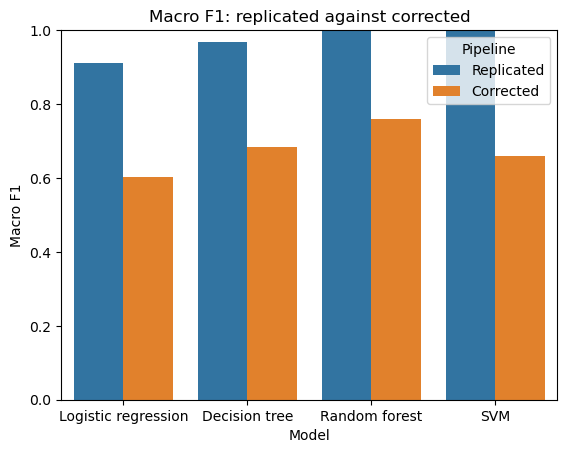

In [9]:
# putting the paper, replicated and corrected results side by side
comparison = pd.DataFrame({
    'Paper accuracy (%)': results_pub['Paper accuracy (%)'],
    'Replicated accuracy (%)': results_pub['Accuracy (%)'],
    'Corrected accuracy (%)': results_cor['Accuracy (%)'],
    'Replicated macro F1': results_pub['Macro F1'],
    'Corrected macro F1': results_cor['Macro F1']})
print(comparison)

# plotting macro F1 for both pipelines
plot_data = comparison[['Replicated macro F1', 'Corrected macro F1']]
plot_data = plot_data.reset_index().melt(
    id_vars='Model', var_name='Pipeline', value_name='Macro F1')
plot_data['Pipeline'] = plot_data['Pipeline'].str.replace(' macro F1', '')
sns.barplot(data=plot_data, x='Model', y='Macro F1', hue='Pipeline')
plt.title('Macro F1: replicated against corrected')
plt.ylim(0, 1)
plt.show()

# Finding

With SMOTE before the split, the four models reach 91.25% to 99.75% accuracy and macro F1 0.911 to 0.997 on a 400-row test set that holds 80 rows per class, including 80 suspect blood donor rows although only 7 exist. Split first, the test set holds 93 real patients, and macro F1 is 0.603 (logistic regression), 0.684 (decision tree), 0.759 (random forest) and 0.659 (SVM). Accuracy stays at 93.55% to 95.70% because 81 of the 93 patients are blood donors, so macro F1 shows the drop.

# **Limits**

- The study does not state its random seed, stratification, scaler, SMOTE settings or winsorising limits. The study's confusion matrices hold 73 to 90 rows per class, so its split may not be stratified. Used here: random_state=42, stratified splits, StandardScaler, SMOTE with k_neighbors=4 and 5th and 95th percentile limits.
- The replication therefore approximates the study, and its numbers will not match the published ones exactly.
- The corrected test set has about 93 real patients, with very few in each disease class and about one suspect blood donor. The results come from a single split, so one patient changes a class score a lot.
- SMOTE gives synthetic rows a fractional value for sex. This is left as it is in both sections.